In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.utils import resample

In [6]:
df = pd.read_csv("dataset_sentimen.csv")

df = df.dropna(subset=["clean_text", "sentimen"])

df["clean_text"] = df["clean_text"].astype(str)
df["sentimen"] = df["sentimen"].astype(str).str.lower().str.strip()

df = df[df["clean_text"].str.strip() != ""]
df = df[df["sentimen"].isin(["negatif", "netral", "positif"])]

print("Jumlah data:", len(df))
df.head()

Jumlah data: 448


,created_at,username,full_text,video_id,clean_text,sentimen
0,2024-02-24T12:53:38Z,@patrick-nl1qk,Loh gula bahaya ta? Pantes waktu dia senyum ha...,lWgMrh_Mxc0,loh gula bahaya ta pantes waktu dia senyum hat...,netral
1,2024-02-25T11:50:48Z,@zaidamar1496,Kebijakan yang ditetapin Singapura bagus bange...,lWgMrh_Mxc0,kebijakan yang ditetapin singapura bagus bange...,positif
2,2024-02-27T04:14:48Z,@newkidz,"Tapi kadar gula orang Indo emang gila sih, say...",lWgMrh_Mxc0,tapi kadar gula orang indo emang gila sih saya...,netral
3,2024-02-25T19:37:19Z,@nandayga,Rangking makanan manis adalah solusi paling ba...,lWgMrh_Mxc0,rangking makanan manis adalah solusi paling ba...,positif
4,2024-02-24T13:02:50Z,@mabackhurts2294,Untung di videonya dijelasin kalo gula ini bah...,lWgMrh_Mxc0,untung di videonya dijelasin kalo gula ini bah...,negatif


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["sentimen"],
    test_size=0.2,
    random_state=42,
    stratify=df["sentimen"]
)

print("Data training:", len(X_train))
print("Data testing:", len(X_test))

Data training: 358
Data testing: 90


In [8]:
from imblearn.over_sampling import RandomOverSampler

# Inisialisasi Random Oversampling
ros = RandomOverSampler(random_state=42)

# Menyeimbangkan data training
X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train.to_frame(name="clean_text"),
    y_train
)

# Mengubah kembali menjadi Series
X_train_resampled = X_train_resampled["clean_text"]

print("Distribusi sebelum oversampling:")
print(y_train.value_counts())

print("\nDistribusi setelah oversampling:")
print(y_train_resampled.value_counts())

Distribusi sebelum oversampling:
sentimen
netral     211
positif     93
negatif     54
Name: count, dtype: int64

Distribusi setelah oversampling:
sentimen
netral     211
positif    211
negatif    211
Name: count, dtype: int64


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion

# TF-IDF berbasis kata
tfidf_word = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True,
    min_df=1
)

# TF-IDF berbasis karakter
tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=5000,
    sublinear_tf=True,
    min_df=1
)

# Menggabungkan fitur Word dan Character
vectorizer = FeatureUnion([
    ("word", tfidf_word),
    ("char", tfidf_char)
])

# Melakukan ekstraksi fitur
X_train_tfidf = vectorizer.fit_transform(X_train_resampled)
X_test_tfidf = vectorizer.transform(X_test)

print("Ukuran fitur training:", X_train_tfidf.shape)
print("Ukuran fitur testing:", X_test_tfidf.shape)

Ukuran fitur training: (633, 10000)
Ukuran fitur testing: (90, 10000)


In [10]:
from sklearn.neural_network import MLPClassifier

# Inisialisasi model Neural Network
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.0005,
    max_iter=400,
    early_stopping=False,
    batch_size=16,
    n_iter_no_change=25,
    random_state=42
)

print("Model Neural Network berhasil dibuat!")

Model Neural Network berhasil dibuat!


In [11]:
# Melatih model Neural Network
model.fit(X_train_tfidf, y_train_resampled)

print("Training model selesai!")
print("Jumlah iterasi:", model.n_iter_)

Training model selesai!
Jumlah iterasi: 78


In [12]:
# Melakukan prediksi pada data testing
y_pred = model.predict(X_test_tfidf)

print("Prediksi data testing berhasil!")
print("Jumlah data yang diprediksi:", len(y_pred))

Prediksi data testing berhasil!
Jumlah data yang diprediksi: 90


In [13]:
from sklearn.metrics import accuracy_score, classification_report

# Menghitung akurasi
accuracy = accuracy_score(y_test, y_pred)

print("================================")
print("HASIL EVALUASI MODEL")
print("================================")

print(f"Akurasi Model: {accuracy * 100:.2f}%")

# Menampilkan classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

HASIL EVALUASI MODEL
Akurasi Model: 74.44%

Classification Report:
              precision    recall  f1-score   support

     negatif       0.71      0.38      0.50        13
      netral       0.75      0.87      0.81        53
     positif       0.73      0.67      0.70        24

    accuracy                           0.74        90
   macro avg       0.73      0.64      0.67        90
weighted avg       0.74      0.74      0.73        90



In [14]:
from sklearn.metrics import f1_score

macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Macro F1-Score: {macro_f1:.4f}")

Macro F1-Score: 0.6676


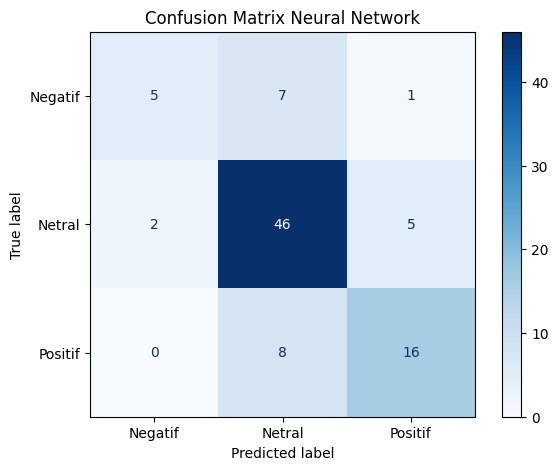

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Membuat confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negatif", "netral", "positif"]
)

# Visualisasi confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negatif", "Netral", "Positif"]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title("Confusion Matrix Neural Network")
plt.show()

In [16]:
import os
import joblib

# Membuat folder penyimpanan
os.makedirs("model", exist_ok=True)

# Menyimpan model dan vectorizer
joblib.dump(
    {
        "model": model,
        "vectorizer": vectorizer
    },
    "model/model_neural_network_word_char.pkl"
)

print("Model dan vectorizer berhasil disimpan!")

Model dan vectorizer berhasil disimpan!


In [17]:
hasil_prediksi = pd.DataFrame({
    "teks_asli": X_test.values,
    "sentimen_aktual": y_test.values,
    "sentimen_prediksi": y_pred
})

hasil_prediksi.to_csv(
    "output/hasil_prediksi_nn_word_char.csv",
    index=False
)

print("Hasil prediksi berhasil disimpan!")

Hasil prediksi berhasil disimpan!


In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

hasil_evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-Score Macro"
    ],
    "Nilai": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ]
})

hasil_evaluasi.to_csv(
    "output/evaluasi_nn_word_char.csv",
    index=False
)

print(hasil_evaluasi)
print("\nHasil evaluasi berhasil disimpan!")

            Metrik     Nilai
0         Accuracy  0.744444
1  Precision Macro  0.731886
2     Recall Macro  0.639736
3   F1-Score Macro  0.667557

Hasil evaluasi berhasil disimpan!


<Figure size 700x500 with 0 Axes>

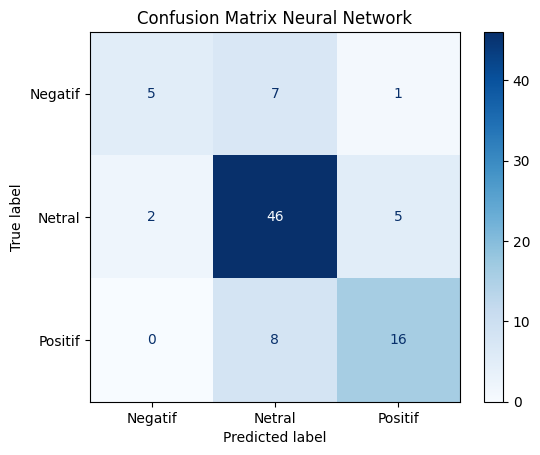

Confusion Matrix berhasil disimpan!


In [19]:
plt.figure(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negatif", "Netral", "Positif"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix Neural Network")
plt.savefig(
    "output/confusion_matrix_nn_word_char.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix berhasil disimpan!")